In [4]:

import platform
import sys

print("Python version:", sys.version)
print("Processor:", platform.machine())

try:
    import torch
    print("PyTorch version:", torch.__version__)
    print("MPS available:", torch.backends.mps.is_available())
    print("CUDA available:", torch.cuda.is_available())
except ImportError:
    print("PyTorch is not installed.")


Python version: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
Processor: AMD64
PyTorch version: 2.15.0+cu132
MPS available: False
CUDA available: True


In [5]:

import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)


Python executable: C:\Users\ilker\AppData\Local\Python\pythoncore-3.14-64\python.exe
Python version: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]


In [6]:

import sys
import torch
import torchvision

print("Python:", sys.version)
print("Python environment:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("MPS available:", torch.backends.mps.is_available())


Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
Python environment: C:\Users\ilker\AppData\Local\Python\pythoncore-3.14-64\python.exe
PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132
MPS available: False



# IAI600 - CIFAR-10 Image Classification Project

## 1. Dataset Loading and Exploration

This project compares Multilayer Perceptron (MLP) and
Convolutional Neural Network (CNN) architectures
for image classification using the CIFAR-10 dataset.


In [7]:

import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

from torchvision.datasets import CIFAR10

# Use Apple GPU if available
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Device:", device)

# Convert images into PyTorch tensors
transform = transforms.ToTensor()

# Download training dataset
train_dataset = CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download test dataset
test_dataset = CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# CIFAR-10 classes
classes = train_dataset.classes

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)
print("Classes:", classes)


Device: cpu


100.0%


Training images: 50000
Test images: 10000
Image shape: torch.Size([3, 32, 32])
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']



## 1.2 Dataset Visualization

In this section, we visualize sample images from
the CIFAR-10 dataset to understand its structure,
image characteristics, and class labels.


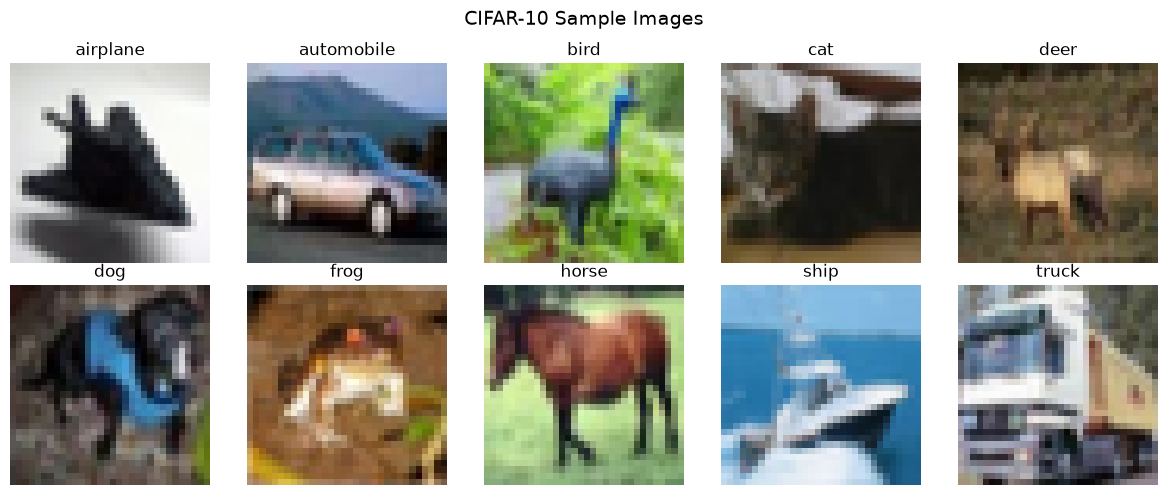

In [8]:

import matplotlib.pyplot as plt
import numpy as np

# CIFAR-10 class names
classes = train_dataset.classes

# Display one example from each class
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for class_idx in range(10):

    # Find the first image belonging to this class
    image_idx = train_dataset.targets.index(class_idx)

    # Get image and label
    image, label = train_dataset[image_idx]

    # Convert from [C, H, W] to [H, W, C]
    image = image.permute(1, 2, 0).numpy()

    # Display image
    ax = axes[class_idx // 5, class_idx % 5]
    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.suptitle("CIFAR-10 Sample Images", fontsize=14)
plt.tight_layout()
plt.show()



## 1.3 Class Distribution Analysis

This section examines the number of images in each
CIFAR-10 class to determine whether the dataset
is balanced across all categories.


Class Distribution:
---------------------------------------------
airplane     | Train:  5000 | Test:  1000
automobile   | Train:  5000 | Test:  1000
bird         | Train:  5000 | Test:  1000
cat          | Train:  5000 | Test:  1000
deer         | Train:  5000 | Test:  1000
dog          | Train:  5000 | Test:  1000
frog         | Train:  5000 | Test:  1000
horse        | Train:  5000 | Test:  1000
ship         | Train:  5000 | Test:  1000
truck        | Train:  5000 | Test:  1000


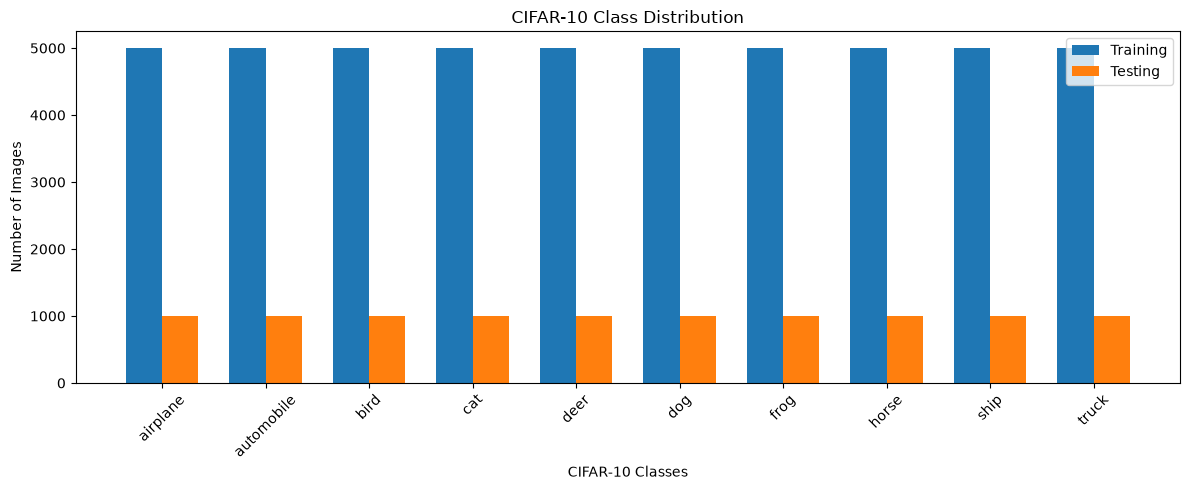

In [9]:

import numpy as np
import matplotlib.pyplot as plt

# Count images for each class
train_counts = np.bincount(
    train_dataset.targets, minlength=10
)

test_counts = np.bincount(
    test_dataset.targets, minlength=10
)

# Display the number of images
print("Class Distribution:")
print("-" * 45)

for i, class_name in enumerate(classes):
    print(
        f"{class_name:12s} | "
        f"Train: {train_counts[i]:5d} | "
        f"Test: {test_counts[i]:5d}"
    )

# Create bar chart
x = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width/2,
    train_counts,
    width,
    label="Training"
)

plt.bar(
    x + width/2,
    test_counts,
    width,
    label="Testing"
)

plt.xlabel("CIFAR-10 Classes")
plt.ylabel("Number of Images")
plt.title("CIFAR-10 Class Distribution")
plt.xticks(x, classes, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()



## 1.4 Stratified Train/Validation Split

The original CIFAR-10 training dataset contains
50,000 images.

We split this dataset into 90% training and
10% validation data using stratified sampling.

Stratification preserves the class distribution,
ensuring that all 10 classes are equally represented.

A fixed random seed (42) is used for reproducibility.
The original test set remains unchanged.


In [10]:

from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import numpy as np

# Original labels from CIFAR-10 training dataset
labels = np.array(train_dataset.targets)

# Indices for all 50,000 training images
indices = np.arange(len(train_dataset))

# Stratified split: 90% training, 10% validation
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.10,
    random_state=42,
    stratify=labels
)

# Create training and validation subsets
train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(train_dataset, val_indices)

# Verify dataset sizes
print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Test samples:", len(test_dataset))

# Verify class distribution
train_labels = labels[train_indices]
val_labels = labels[val_indices]

print("\nClass Distribution After Split:")
print("-" * 45)

for i, class_name in enumerate(classes):
    train_count = np.sum(train_labels == i)
    val_count = np.sum(val_labels == i)

    print(
        f"{class_name:12s} | "
        f"Train: {train_count:5d} | "
        f"Validation: {val_count:4d}"
    )


Training samples: 45000
Validation samples: 5000
Test samples: 10000

Class Distribution After Split:
---------------------------------------------
airplane     | Train:  4500 | Validation:  500
automobile   | Train:  4500 | Validation:  500
bird         | Train:  4500 | Validation:  500
cat          | Train:  4500 | Validation:  500
deer         | Train:  4500 | Validation:  500
dog          | Train:  4500 | Validation:  500
frog         | Train:  4500 | Validation:  500
horse        | Train:  4500 | Validation:  500
ship         | Train:  4500 | Validation:  500
truck        | Train:  4500 | Validation:  500



## 1.5 Data Normalization

We compute channel-wise mean and standard deviation
using only the training subset.

The same normalization parameters will be applied
to training, validation, and test images to avoid
data leakage and ensure consistent preprocessing.


In [11]:

from torch.utils.data import DataLoader

# Temporary DataLoader for computing statistics
stats_loader = DataLoader(
    train_subset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
total_pixels = 0

for images, labels_batch in stats_loader:
    channel_sum += images.sum(dim=(0, 2, 3))
    channel_sum_sq += (images ** 2).sum(dim=(0, 2, 3))
    total_pixels += images.shape[0] * images.shape[2] * images.shape[3]

mean = channel_sum / total_pixels
std = torch.sqrt(
    channel_sum_sq / total_pixels - mean ** 2
)

print("Training mean:", mean)
print("Training std:", std)


Training mean: tensor([0.4911, 0.4821, 0.4464])
Training std: tensor([0.2469, 0.2434, 0.2616])


In [12]:

from torchvision import transforms
from torchvision.datasets import CIFAR10
from torch.utils.data import Subset

# Normalization transform
normalized_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean.tolist(),
        std=std.tolist()
    )
])

# Load the existing datasets with normalization
normalized_train_full = CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=normalized_transform
)

normalized_test = CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=normalized_transform
)

# Reuse exactly the same indices
train_final = Subset(normalized_train_full, train_indices)
val_final = Subset(normalized_train_full, val_indices)
test_final = normalized_test

print("Training:", len(train_final))
print("Validation:", len(val_final))
print("Testing:", len(test_final))


Training: 45000
Validation: 5000
Testing: 10000


In [13]:

from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_final,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_final,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_final,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Verify one batch
images, labels = next(iter(train_loader))

print("Batch images shape:", images.shape)
print("Batch labels shape:", labels.shape)
print("Image dtype:", images.dtype)


Batch images shape: torch.Size([64, 3, 32, 32])
Batch labels shape: torch.Size([64])
Image dtype: torch.float32



## 1.6 Final Preprocessing Verification

This section verifies that the normalized training
dataset has approximately zero channel-wise mean
and unit standard deviation.

It also verifies that the training, validation,
and test datasets contain the expected samples.


In [14]:

# Verify normalization using the complete training set
channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
total_pixels = 0

for images_batch, _ in train_loader:
    channel_sum += images_batch.sum(dim=(0, 2, 3))
    channel_sum_sq += (images_batch ** 2).sum(dim=(0, 2, 3))
    total_pixels += images_batch.shape[0] * 32 * 32

verified_mean = channel_sum / total_pixels
verified_std = torch.sqrt(
    channel_sum_sq / total_pixels - verified_mean ** 2
)

print("Normalized training mean:", verified_mean)
print("Normalized training std:", verified_std)

print("\nDataset sizes:")
print("Training:", len(train_final))
print("Validation:", len(val_final))
print("Test:", len(test_final))

# Final checks
assert len(train_final) == 45000
assert len(val_final) == 5000
assert len(test_final) == 10000

assert set(train_indices).isdisjoint(set(val_indices))

assert torch.allclose(
    verified_mean, torch.zeros(3), atol=1e-4
)

assert torch.allclose(
    verified_std, torch.ones(3), atol=1e-4
)

print("\nAll preprocessing checks passed!")


Normalized training mean: tensor([ 1.4217e-07,  5.4802e-07, -4.8388e-08])
Normalized training std: tensor([1.0000, 1.0000, 1.0000])

Dataset sizes:
Training: 45000
Validation: 5000
Test: 10000

All preprocessing checks passed!



## 1.7 Reproducibility and Group Handoff

We save the exact training and validation indices
and normalization parameters to ensure that the
MLP and CNN models use identical data partitions
and preprocessing settings.


In [15]:

import json
from pathlib import Path

# Create a folder for shared configuration files
config_dir = Path("config")
config_dir.mkdir(exist_ok=True)

# Save exact dataset indices
np.savez(
    config_dir / "split_indices.npz",
    train_indices=train_indices,
    val_indices=val_indices
)

# Save preprocessing parameters
config = {
    "dataset": "CIFAR-10",
    "random_state": 42,
    "training_samples": 45000,
    "validation_samples": 5000,
    "test_samples": 10000,
    "batch_size": BATCH_SIZE,
    "mean": mean.tolist(),
    "std": std.tolist(),
    "classes": classes
}

with open(
    config_dir / "preprocessing_config.json",
    "w"
) as file:
    json.dump(config, file, indent=4)

print("Configuration files saved successfully!")
print("Files:")
print(config_dir / "split_indices.npz")
print(config_dir / "preprocessing_config.json")


Configuration files saved successfully!
Files:
config\split_indices.npz
config\preprocessing_config.json



## 1.8 Configuration Verification

This section verifies that the saved preprocessing
configuration and dataset indices can be reloaded
correctly for reproducible experiments.


In [16]:

import json
import numpy as np

# Load saved dataset indices
saved_indices = np.load("config/split_indices.npz")

saved_train = saved_indices["train_indices"]
saved_val = saved_indices["val_indices"]

# Load saved preprocessing configuration
with open("config/preprocessing_config.json", "r") as file:
    saved_config = json.load(file)

# Verify saved values
assert np.array_equal(saved_train, train_indices)
assert np.array_equal(saved_val, val_indices)

assert len(saved_train) == 45000
assert len(saved_val) == 5000

assert np.allclose(saved_config["mean"], mean.numpy())
assert np.allclose(saved_config["std"], std.numpy())

print("Training indices:", len(saved_train))
print("Validation indices:", len(saved_val))
print("Saved mean:", saved_config["mean"])
print("Saved std:", saved_config["std"])
print("Batch size:", saved_config["batch_size"])

print("\nAll configuration checks passed!")


Training indices: 45000
Validation indices: 5000
Saved mean: [0.4911373257637024, 0.4821110665798187, 0.44644901156425476]
Saved std: [0.246869295835495, 0.24343018233776093, 0.261603444814682]
Batch size: 64

All configuration checks passed!


In [17]:

from data_preparation import get_cifar10_loaders

# Load datasets using the shared module
train_loader_shared, val_loader_shared, test_loader_shared = (
    get_cifar10_loaders()
)

# Check dataset sizes
print("Training:", len(train_loader_shared.dataset))
print("Validation:", len(val_loader_shared.dataset))
print("Testing:", len(test_loader_shared.dataset))

# Check one batch
images, labels = next(iter(train_loader_shared))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)

print("\nShared data preparation module works!")


Training: 45000
Validation: 5000
Testing: 10000

Batch image shape: torch.Size([64, 3, 32, 32])
Batch label shape: torch.Size([64])

Shared data preparation module works!


In [19]:

from pathlib import Path

Path("gitignore.txt").rename(".gitignore")

print(".gitignore file created successfully!")


FileNotFoundError: [WinError 2] Sistem belirtilen dosyayı bulamıyor: 'gitignore.txt' -> '.gitignore'

In [20]:

from pathlib import Path

print(".gitignore exists:", Path(".gitignore").exists())
print("gitignore.txt exists:", Path("gitignore.txt").exists())


.gitignore exists: True
gitignore.txt exists: False


In [21]:


print("Current folder:", Path.cwd())
print(".gitignore exists:", Path(".gitignore").exists())
print("gitignore.txt exists:", Path("gitignore.txt").exists())

if Path(".gitignore").exists():
    print("File location:", Path(".gitignore").resolve())


Current folder: C:\Users\user\Documents\GitHub\CIFAR10-Image-Classification
.gitignore exists: True
gitignore.txt exists: False
File location: C:\Users\user\Documents\GitHub\CIFAR10-Image-Classification\.gitignore


In [18]:
import torch
from torch import nn
from copy import deepcopy

torch.manual_seed(42)

train_loader = train_loader_shared
val_loader = val_loader_shared

# each image has 32 × 32 × 3 = 3072 values
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3072, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mlp.parameters(), lr=0.001)

best_accuracy = -1
best_weights = deepcopy(mlp.state_dict())

for epoch in range(10):

    # train the model using batches of images
    mlp.train()
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = mlp(images)
        loss = loss_function(outputs, labels)

        loss.backward()
        optimizer.step()

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    # Check validation accuracy without updating the model
    mlp.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = mlp(images)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    train_accuracy = train_correct / train_total
    val_accuracy = val_correct / val_total

    # Keep a copy whenever validation accuracy improves
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_weights = deepcopy(mlp.state_dict())

    print(
        f"Epoch {epoch + 1}: "
        f"Training = {train_accuracy:.2%}, "
        f"Validation = {val_accuracy:.2%}"
    )

# Restore and save the best model
mlp.load_state_dict(best_weights)
mlp.eval()
torch.save(mlp.state_dict(), "mlp_weights.pth")

print(f"\nBest validation accuracy: {best_accuracy:.2%}")

Epoch 1: Training = 41.05%, Validation = 44.92%
Epoch 2: Training = 47.92%, Validation = 46.76%
Epoch 3: Training = 50.78%, Validation = 48.04%
Epoch 4: Training = 53.10%, Validation = 50.14%
Epoch 5: Training = 54.66%, Validation = 50.24%
Epoch 6: Training = 56.38%, Validation = 49.48%
Epoch 7: Training = 57.90%, Validation = 51.20%
Epoch 8: Training = 59.17%, Validation = 49.36%
Epoch 9: Training = 60.40%, Validation = 50.38%
Epoch 10: Training = 61.43%, Validation = 49.44%

Best validation accuracy: 51.20%


# SVM Model


In [19]:
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Test images:", len(test_loader.dataset))

Training images: 45000
Validation images: 5000
Test images: 10000


In [20]:
import data_preparation

print("Data preparation module:", data_preparation.__file__)
print("Available dataset objects:")
print([name for name in dir(data_preparation) if "dataset" in name.lower()])

Data preparation module: C:\Users\ilker\Documents\GitHub\CIFAR10-Image-Classification\data_preparation.py
Available dataset objects:
[]


In [1]:
from data_preparation import get_cifar10_loaders

train_loader, val_loader, test_loader = get_cifar10_loaders(
    project_dir=".",
    download=False
)

print("Training:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))
print("Testing:", len(test_loader.dataset))

Training: 45000
Validation: 5000
Testing: 10000


In [2]:
import numpy as np

def loader_to_numpy(loader):
    images_list = []
    labels_list = []

    for images, labels in loader:
        images_list.append(images.numpy())
        labels_list.append(labels.numpy())

    X = np.concatenate(images_list, axis=0)
    y = np.concatenate(labels_list, axis=0)

    X = X.reshape(X.shape[0], -1)

    return X, y


X_train, y_train = loader_to_numpy(train_loader)
X_val, y_val = loader_to_numpy(val_loader)
X_test, y_test = loader_to_numpy(test_loader)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (45000, 3072) (45000,)
Validation: (5000, 3072) (5000,)
Testing: (10000, 3072) (10000,)


In [3]:
# 2000 samples C=1.0
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import time

# Select 2,000 balanced training samples
X_train_small, _, y_train_small, _ = train_test_split(
    X_train,
    y_train,
    train_size=2000,
    random_state=42,
    stratify=y_train
)

# Create the Linear SVM
svm_model = LinearSVC(
    C=1.0,
    max_iter=1000,
    random_state=42,
    dual="auto"
)

# Train
start_time = time.time()

svm_model.fit(X_train_small, y_train_small)

training_time = time.time() - start_time

# Validate
val_predictions = svm_model.predict(X_val)
svm_val_accuracy = accuracy_score(y_val, val_predictions)

print(f"Training samples: {len(X_train_small)}")
print(f"Training time: {training_time:.2f} seconds")
print(f"Validation accuracy: {svm_val_accuracy * 100:.2f}%")
print("Iterations per class:", svm_model.n_iter_)

Training samples: 2000
Training time: 54.01 seconds
Validation accuracy: 22.96%
Iterations per class: 1000


C:\Users\ilker\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [4]:
print("Training time:", training_time)
print("Validation accuracy:", svm_val_accuracy * 100)
print("Iterations per class:", svm_model.n_iter_)

Training time: 54.014965772628784
Validation accuracy: 22.96
Iterations per class: 1000


In [5]:
#2000 samples C=0.01
svm_model_v2 = LinearSVC(
    C=0.01,
    max_iter=3000,
    random_state=42,
    dual="auto"
)

start_time = time.time()

svm_model_v2.fit(X_train_small, y_train_small)

training_time_v2 = time.time() - start_time

val_predictions_v2 = svm_model_v2.predict(X_val)
svm_val_accuracy_v2 = accuracy_score(y_val, val_predictions_v2)

print(f"Training time: {training_time_v2:.2f} seconds")
print(f"Validation accuracy: {svm_val_accuracy_v2 * 100:.2f}%")
print("Iterations per class:", svm_model_v2.n_iter_)

Training time: 74.75 seconds
Validation accuracy: 26.12%
Iterations per class: 1336


In [7]:
#2000 samples c=0.001
svm_model_v3 = LinearSVC(
    C=0.001,
    max_iter=3000,
    random_state=42,
    dual="auto"
)

start_time = time.time()

svm_model_v3.fit(X_train_small, y_train_small)

training_time_v3 = time.time() - start_time

val_predictions_v3 = svm_model_v3.predict(X_val)
svm_val_accuracy_v3 = accuracy_score(y_val, val_predictions_v3)

print(f"Training time: {training_time_v3:.2f} seconds")
print(f"Validation accuracy: {svm_val_accuracy_v3 * 100:.2f}%")
print("Iterations per class:", svm_model_v3.n_iter_)

Training time: 16.86 seconds
Validation accuracy: 31.04%
Iterations per class: 168


In [8]:
best_svm_model = svm_model_v3
best_svm_C = 0.001
best_svm_val_accuracy = svm_val_accuracy_v3

print("Best SVM C:", best_svm_C)
print("Best validation accuracy:", best_svm_val_accuracy * 100)

Best SVM C: 0.001
Best validation accuracy: 31.04


In [9]:
# split to 10000 samples
X_train_10k, _, y_train_10k, _ = train_test_split(
    X_train,
    y_train,
    train_size=10000,
    random_state=42,
    stratify=y_train
)

print("SVM training features:", X_train_10k.shape)
print("SVM training labels:", y_train_10k.shape)

SVM training features: (10000, 3072)
SVM training labels: (10000,)


In [10]:
# 10000 samples c=0.001
svm_model_10k = LinearSVC(
    C=0.001,
    max_iter=3000,
    random_state=42,
    dual="auto"
)

start_time = time.time()

svm_model_10k.fit(X_train_10k, y_train_10k)

training_time_10k = time.time() - start_time

val_predictions_10k = svm_model_10k.predict(X_val)
svm_val_accuracy_10k = accuracy_score(y_val, val_predictions_10k)

print(f"Training time: {training_time_10k:.2f} seconds")
print(f"Validation accuracy: {svm_val_accuracy_10k * 100:.2f}%")
print("Iterations per class:", svm_model_10k.n_iter_)

Training time: 135.21 seconds
Validation accuracy: 36.28%
Iterations per class: 7


In [11]:
#10000 samples c=0.0001
svm_model_10k_v2 = LinearSVC(
    C=0.0001,
    max_iter=3000,
    random_state=42,
    dual="auto"
)

start_time = time.time()

svm_model_10k_v2.fit(X_train_10k, y_train_10k)

training_time_10k_v2 = time.time() - start_time

val_predictions_10k_v2 = svm_model_10k_v2.predict(X_val)
svm_val_accuracy_10k_v2 = accuracy_score(
    y_val,
    val_predictions_10k_v2
)

print(f"Training time: {training_time_10k_v2:.2f} seconds")
print(f"Validation accuracy: {svm_val_accuracy_10k_v2 * 100:.2f}%")
print("Iterations per class:", svm_model_10k_v2.n_iter_)

Training time: 72.37 seconds
Validation accuracy: 38.88%
Iterations per class: 6


In [12]:
# 10000 samples c=0.00001
svm_model_10k_v3 = LinearSVC(
    C=0.00001,
    max_iter=3000,
    random_state=42,
    dual="auto"
)

start_time = time.time()

svm_model_10k_v3.fit(X_train_10k, y_train_10k)

training_time_10k_v3 = time.time() - start_time

val_predictions_10k_v3 = svm_model_10k_v3.predict(X_val)

svm_val_accuracy_10k_v3 = accuracy_score(
    y_val, val_predictions_10k_v3
)

print(f"Training time: {training_time_10k_v3:.2f} seconds")
print(f"Validation accuracy: {svm_val_accuracy_10k_v3 * 100:.2f}%")
print("Iterations per class:", svm_model_10k_v3.n_iter_)

Training time: 39.23 seconds
Validation accuracy: 37.52%
Iterations per class: 5


In [13]:
svm_results = [
    {"C": 0.001, "samples": 10000,
     "time": training_time_10k, "accuracy": svm_val_accuracy_10k},
    {"C": 0.0001, "samples": 10000,
     "time": training_time_10k_v2, "accuracy": svm_val_accuracy_10k_v2},
    {"C": 0.00001, "samples": 10000,
     "time": training_time_10k_v3, "accuracy": svm_val_accuracy_10k_v3}
]

for result in svm_results:
    print(result)

{'C': 0.001, 'samples': 10000, 'time': 135.21397304534912, 'accuracy': 0.3628}
{'C': 0.0001, 'samples': 10000, 'time': 72.37216067314148, 'accuracy': 0.3888}
{'C': 1e-05, 'samples': 10000, 'time': 39.228761434555054, 'accuracy': 0.3752}


In [14]:
# 45000 samples c=0.0001
svm_model_final = LinearSVC(
    C=0.0001,
    max_iter=3000,
    random_state=42,
    dual="auto"
)

start_time = time.time()

svm_model_final.fit(X_train, y_train)

training_time_final = time.time() - start_time

val_predictions_final = svm_model_final.predict(X_val)

svm_val_accuracy_final = accuracy_score(
    y_val, val_predictions_final
)

print(f"Training time: {training_time_final:.2f} seconds")
print(f"Validation accuracy: {svm_val_accuracy_final * 100:.2f}%")
print("Iterations per class:", svm_model_final.n_iter_)

Training time: 616.90 seconds
Validation accuracy: 41.10%
Iterations per class: 6


In [15]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    val_predictions_final,
    target_names=[
        "airplane", "automobile", "bird", "cat", "deer",
        "dog", "frog", "horse", "ship", "truck"
    ]
))

              precision    recall  f1-score   support

    airplane       0.45      0.51      0.48       500
  automobile       0.40      0.52      0.45       500
        bird       0.35      0.21      0.27       500
         cat       0.32      0.17      0.22       500
        deer       0.43      0.27      0.33       500
         dog       0.38      0.36      0.37       500
        frog       0.40      0.53      0.46       500
       horse       0.42      0.45      0.44       500
        ship       0.49      0.57      0.53       500
       truck       0.40      0.50      0.45       500

    accuracy                           0.41      5000
   macro avg       0.40      0.41      0.40      5000
weighted avg       0.40      0.41      0.40      5000



In [16]:
test_predictions_svm = svm_model_final.predict(X_test)

from sklearn.metrics import accuracy_score

svm_test_accuracy = accuracy_score(
    y_test,
    test_predictions_svm
)

print(f"SVM Test Accuracy: {svm_test_accuracy * 100:.2f}%")

SVM Test Accuracy: 40.70%


In [19]:
from pathlib import Path

for path in Path(".").rglob("*"):
    if path.is_file() and path.suffix in [".pth", ".pt", ".pkl", ".joblib"]:
        print(path)

cnn_cifar10_regularized.pth
mlp_weights.pth


In [25]:
class MLP(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.Flatten(),
            nn.Linear(3072, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

In [26]:
mlp_model = MLP()

mlp_model.load_state_dict(
    torch.load("mlp_weights.pth", map_location="cpu")
)

mlp_model.eval()

print("MLP weights loaded successfully!")

MLP weights loaded successfully!


In [27]:
from sklearn.metrics import accuracy_score
import numpy as np

mlp_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = mlp_model(images)
        predictions = torch.argmax(outputs, dim=1)
        mlp_predictions.extend(predictions.numpy())

mlp_predictions = np.array(mlp_predictions)

mlp_test_accuracy = accuracy_score(
    y_test, mlp_predictions
)

print(f"MLP Test Accuracy: {mlp_test_accuracy * 100:.2f}%")

MLP Test Accuracy: 50.21%


In [28]:
from sklearn.metrics import classification_report

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("MLP TEST RESULTS")
print(classification_report(
    y_test,
    mlp_predictions,
    target_names=class_names
))

print("SVM TEST RESULTS")
print(classification_report(
    y_test,
    test_predictions_svm,
    target_names=class_names
))

MLP TEST RESULTS
              precision    recall  f1-score   support

    airplane       0.61      0.54      0.57      1000
  automobile       0.63      0.57      0.60      1000
        bird       0.38      0.45      0.42      1000
         cat       0.35      0.19      0.25      1000
        deer       0.46      0.32      0.38      1000
         dog       0.40      0.44      0.42      1000
        frog       0.50      0.61      0.55      1000
       horse       0.52      0.63      0.57      1000
        ship       0.58      0.69      0.63      1000
       truck       0.53      0.57      0.55      1000

    accuracy                           0.50     10000
   macro avg       0.50      0.50      0.49     10000
weighted avg       0.50      0.50      0.49     10000

SVM TEST RESULTS
              precision    recall  f1-score   support

    airplane       0.44      0.50      0.47      1000
  automobile       0.41      0.52      0.46      1000
        bird       0.37      0.22      0.27 

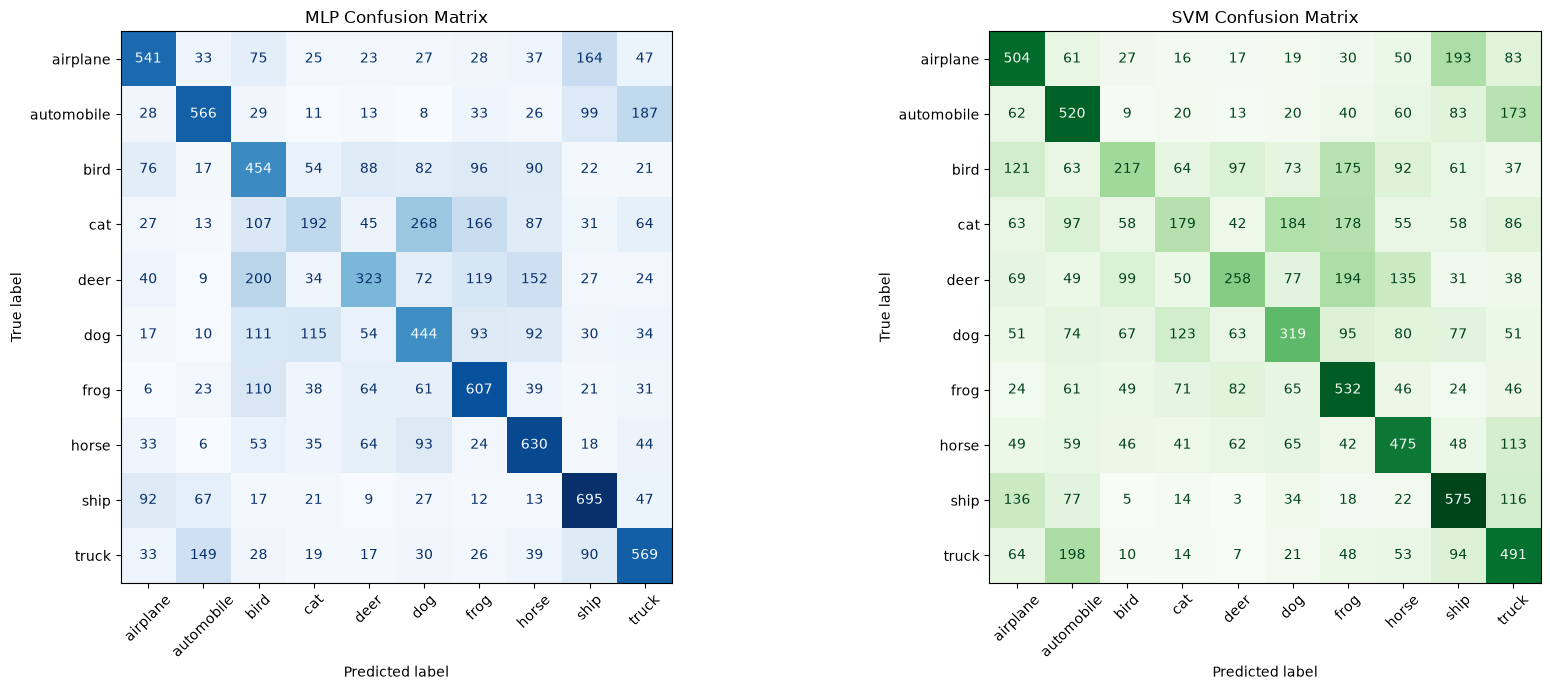

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# MLP confusion matrix
cm_mlp = confusion_matrix(y_test, mlp_predictions)

disp_mlp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=class_names
)

disp_mlp.plot(
    ax=axes[0],
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

axes[0].set_title("MLP Confusion Matrix")

# SVM confusion matrix
cm_svm = confusion_matrix(y_test, test_predictions_svm)

disp_svm = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=class_names
)

disp_svm.plot(
    ax=axes[1],
    cmap="Greens",
    xticks_rotation=45,
    colorbar=False
)

axes[1].set_title("SVM Confusion Matrix")

plt.tight_layout()
plt.show()